In [7]:
# Setup cell
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import os
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

In [8]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Data Reading and  Pre-processing

In [9]:
# Read Weather dataset
df = pd.read_csv('/content/drive/MyDrive/mpi_roof_2025.csv', encoding = "unicode_escape")

# Print first five rows of datatset
df.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m²),PAR (µmol/m²/s),max. PAR (µmol/m²/s),Tlog (degC),CO2 (ppm)
0,01.01.2025 00:10:00,997.30,-1.56,271.80,-2.97,90.0,5.45,4.90,0.54,3.06,...,1.61,3.87,148.9,0.0,0.0,0.0,0.0,0.0,6.24,456.9
1,01.01.2025 00:20:00,997.05,-0.90,272.48,-2.66,87.8,5.72,5.02,0.70,3.14,...,1.71,3.05,145.6,0.0,0.0,0.0,0.0,0.0,6.32,451.7
2,01.01.2025 00:30:00,996.96,-0.51,272.88,-2.44,86.7,5.89,5.10,0.78,3.19,...,1.61,3.31,146.9,0.0,0.0,0.0,0.0,0.0,6.46,451.0
3,01.01.2025 00:40:00,996.77,-0.27,273.14,-2.26,86.3,5.99,5.17,0.82,3.23,...,1.86,2.93,137.0,0.0,0.0,0.0,0.0,0.0,6.63,450.4
4,01.01.2025 00:50:00,996.62,-0.09,273.33,-2.14,86.0,6.07,5.22,0.85,3.26,...,1.25,2.23,131.3,0.0,0.0,0.0,0.0,0.0,6.82,450.4


In [10]:
# Selecting only 'Date Time' and 'T(degC)'
df = df[['Date Time', 'T (degC)']]

# Dropping potential NA values
df = df.dropna()

# Converting to proper date time format
df["Date Time"] = pd.to_datetime(df["Date Time"], format = "mixed")
df = df.set_index("Date Time").asfreq("10min")

df.head()

,T (degC)
Date Time,
2025-01-01 00:10:00,-1.56
2025-01-01 00:20:00,-0.90
2025-01-01 00:30:00,-0.51
2025-01-01 00:40:00,-0.27
2025-01-01 00:50:00,-0.09


In [11]:
# Select rows for short-term forecasting
# Total of 72 hours
df_short = df["2025-01-01":"2025-01-04"]

# Select rows for long-term forecasting
# Total of 5 months
df_long = df["2025-01-01":"2025-05-31"]

print(f"Short-term shape: {df_short.shape}")
print(f"Long-term shape:  {df_long.shape}")

Short-term shape: (575, 1)
Long-term shape:  (21743, 1)


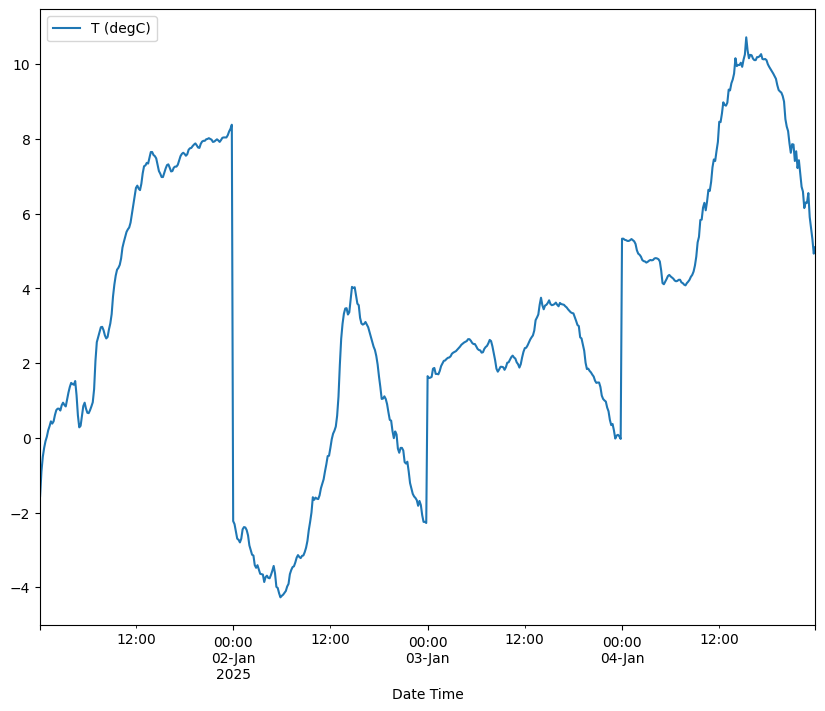

In [12]:
df_short.plot()
plt.show()

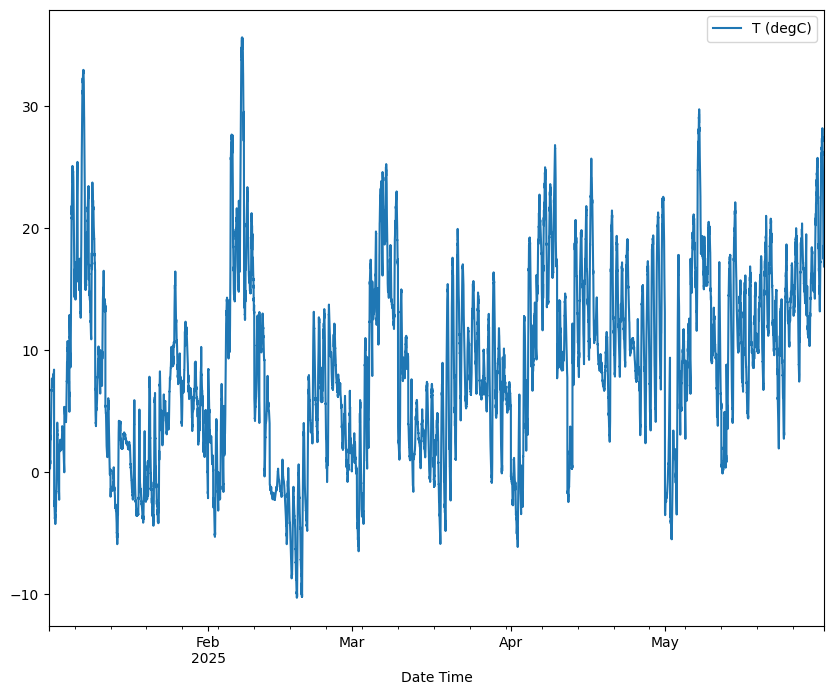

In [13]:
df_long.plot()
plt.show()

/usr/local/lib/python3.12/dist-packages/statsmodels/base/optimizer.py:21: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method lbfgs is: m, pgtol, factr, maxfun, epsilon, approx_grad, bounds, loglike_and_score, iprint. The list of unsupported keyword arguments passed include: optimized. After release 0.14, this will raise.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


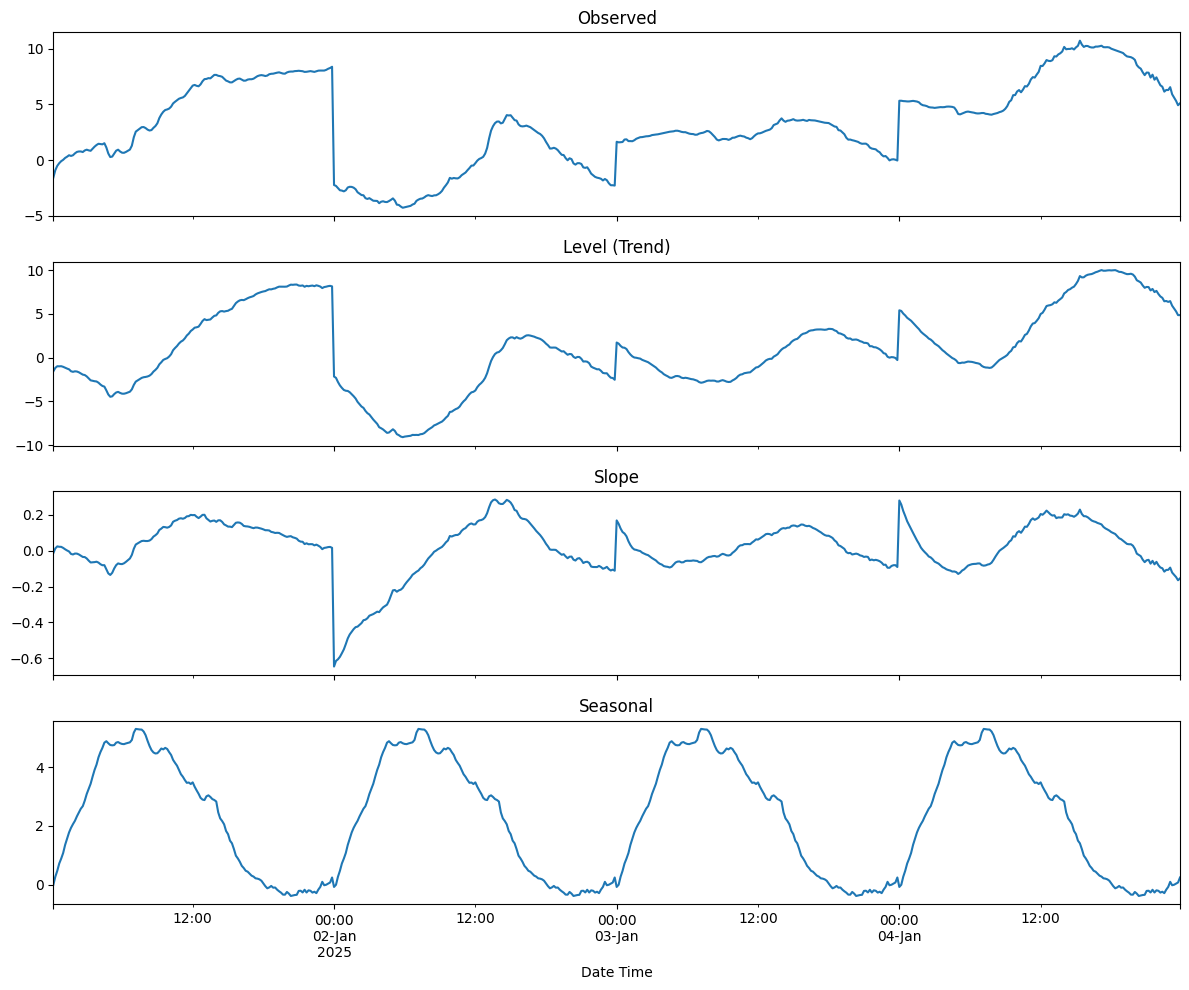

In [14]:
# ETS Decomposition for short forecasting
model_short = ETSModel(
    df_short["T (degC)"],
    error="add",        # Additive error
    trend="add",        # Additive trend
    seasonal="add",     # Additive seasonality
    damped_trend=False,
    seasonal_periods=144  # 144 × 10min = 1 full day
)
fit_short = model_short.fit(optimized=True)

# ETS plot
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

df_short["T (degC)"].plot(ax=axes[0], title="Observed")
fit_short.level.plot(ax=axes[1], title="Level (Trend)")
fit_short.slope.plot(ax=axes[2], title="Slope")
fit_short.season.plot(ax=axes[3], title="Seasonal")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/statsmodels/base/optimizer.py:21: FutureWarning: Keyword arguments have been passed to the optimizer that have no effect. The list of allowed keyword arguments for method lbfgs is: m, pgtol, factr, maxfun, epsilon, approx_grad, bounds, loglike_and_score, iprint. The list of unsupported keyword arguments passed include: optimized. After release 0.14, this will raise.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


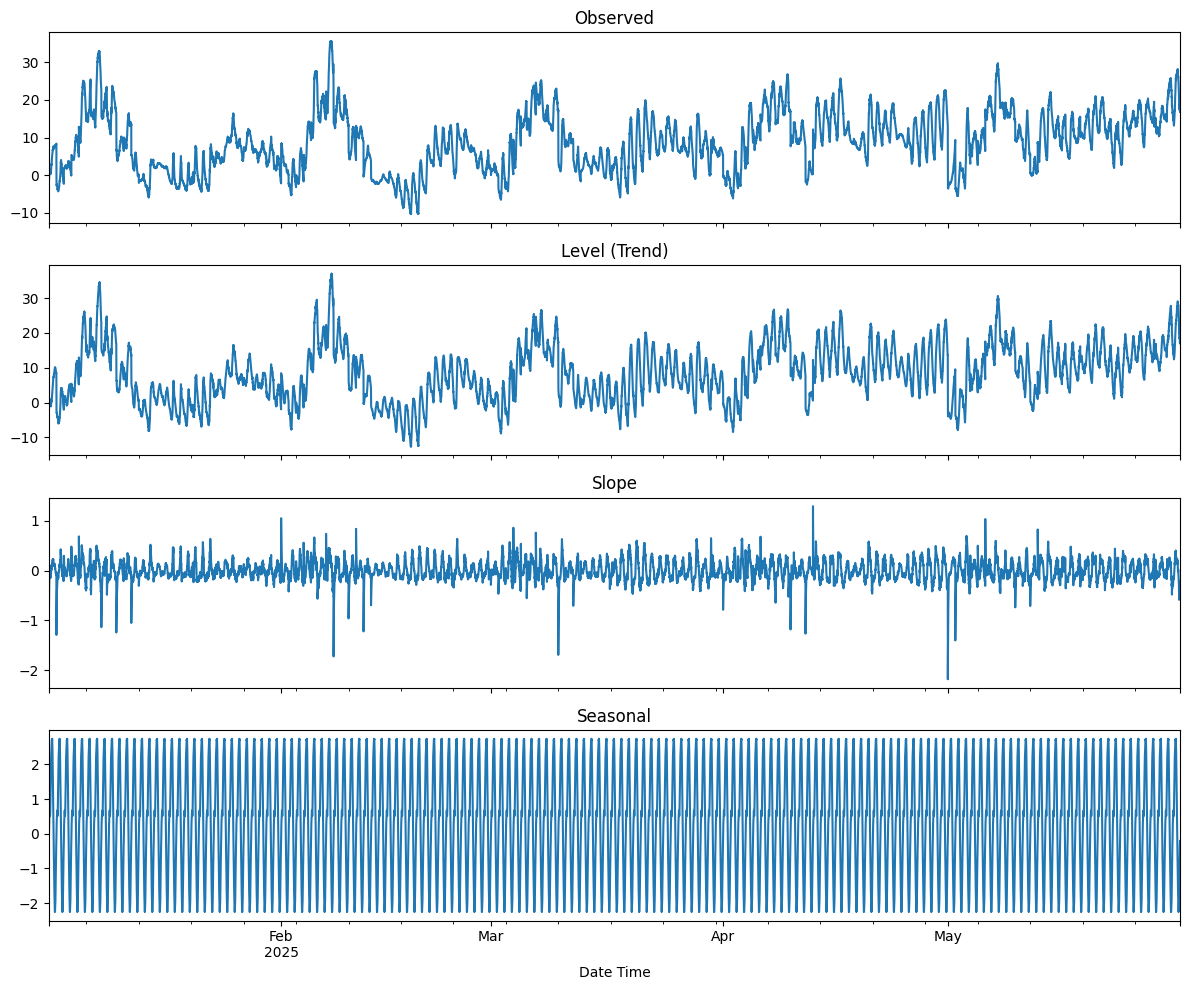

In [15]:
# ETS Decomposition for long forecasting
model_long = ETSModel(
    df_long["T (degC)"],
    error="add",
    trend="add",
    seasonal="add",
    damped_trend=False,
    seasonal_periods=144  # Daily seasonality (144 × 10min = 1 day)
)

fit_long = model_long.fit(optimized=True)

# ETS plot
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

df_long["T (degC)"].plot(ax=axes[0], title="Observed")
fit_long.level.plot(ax=axes[1], title="Level (Trend)")
fit_long.slope.plot(ax=axes[2], title="Slope")
fit_long.season.plot(ax=axes[3], title="Seasonal")

plt.tight_layout()
plt.show()